# EXP 4 - Time Series Analysis and Failure Prediction  
**Dataset:** Sub_Division_IMD_2017.csv (IMD subdivision-wise rainfall, 1901-2017), same dataset as EXP1-EXP3  
**Use case:** KJS-AGR-01 (AI Irrigation Advisory)  
**Roll No:** 16014324020  
  
How the lab terms are mapped onto this dataset:  
- timestamp = YEAR (one reading per subdivision per year)  
- sensor measurements = rainfall columns (JF, MAM, JJAS, OND, ANNUAL)  
- "failure" = a deficient-rainfall (drought) year, defined as ANNUAL rainfall more than 20% below that subdivision's average

## Step 2: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score)

pd.set_option('display.width', 150)

## Step 3: Load the dataset (Result 1 - Dataset information)

In [2]:
df = pd.read_csv("Sub_Division_IMD_2017.csv")
print("Shape:", df.shape)
print("Subdivisions:", df['SUBDIVISION'].nunique(), " Years:", df['YEAR'].min(), "-", df['YEAR'].max())
print(df.head())
df.info()

Shape: (4188, 19)
Subdivisions: 36  Years: 1901 - 2017
                 SUBDIVISION  YEAR   JAN    FEB   MAR    APR    MAY    JUN    JUL    AUG    SEP    OCT    NOV    DEC  ANNUAL     JF    MAM    JJAS  \
0  Andaman & Nicobar Islands  1901  49.2   87.1  29.2    2.3  528.8  517.5  365.1  481.1  332.6  388.5  558.2   33.6  3373.2  136.3  560.3  1696.3   
1  Andaman & Nicobar Islands  1902   0.0  159.8  12.2    0.0  446.1  537.1  228.9  753.7  666.2  197.2  359.0  160.5  3520.7  159.8  458.3  2185.9   
2  Andaman & Nicobar Islands  1903  12.7  144.0   0.0    1.0  235.1  479.9  728.4  326.7  339.0  181.2  284.4  225.0  2957.4  156.7  236.1  1874.0   
3  Andaman & Nicobar Islands  1904   9.4   14.7   0.0  202.4  304.5  495.1  502.0  160.1  820.4  222.2  308.7   40.1  3079.6   24.1  506.9  1977.6   
4  Andaman & Nicobar Islands  1905   1.3    0.0   3.3   26.9  279.5  628.7  368.7  330.5  297.0  260.7   25.4  344.7  2566.7    1.3  309.7  1624.9   

     OND  
0  980.3  
1  716.7  
2  690.6  


## Step 4: Convert timestamp and sort the data

In [3]:
df['date'] = pd.to_datetime(df['YEAR'].astype(str), format='%Y')
df = df.sort_values(['SUBDIVISION', 'date']).reset_index(drop=True)
print(df[['SUBDIVISION', 'YEAR', 'date']].head(3))

                 SUBDIVISION  YEAR       date
0  Andaman & Nicobar Islands  1901 1901-01-01
1  Andaman & Nicobar Islands  1902 1902-01-01
2  Andaman & Nicobar Islands  1903 1903-01-01


## Step 5: Check missing values

In [4]:
sensors = ['JF', 'MAM', 'JJAS', 'OND', 'ANNUAL']
months = ['JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC']
fill_cols = months + sensors

print("Missing values before:", df[fill_cols].isnull().sum().sum())

df[fill_cols] = df.groupby('SUBDIVISION')[fill_cols].transform(lambda s: s.interpolate(limit_direction='both'))
print("Missing values after interpolation:", df[fill_cols].isnull().sum().sum())

full = pd.MultiIndex.from_product([df['SUBDIVISION'].unique(), range(1901, 2018)], names=['SUBDIVISION', 'YEAR'])
ts = df.set_index(['SUBDIVISION', 'YEAR'])[sensors].reindex(full).reset_index()
print("Years missing completely (left empty, not invented):", ts['ANNUAL'].isnull().sum())

Missing values before: 134
Missing values after interpolation: 0
Years missing completely (left empty, not invented): 24


## Step 6: Visualize sensor values over time (Result 2 - Time-series plot)
Konkan & Goa is used for the detailed plots, same as the earlier experiments.

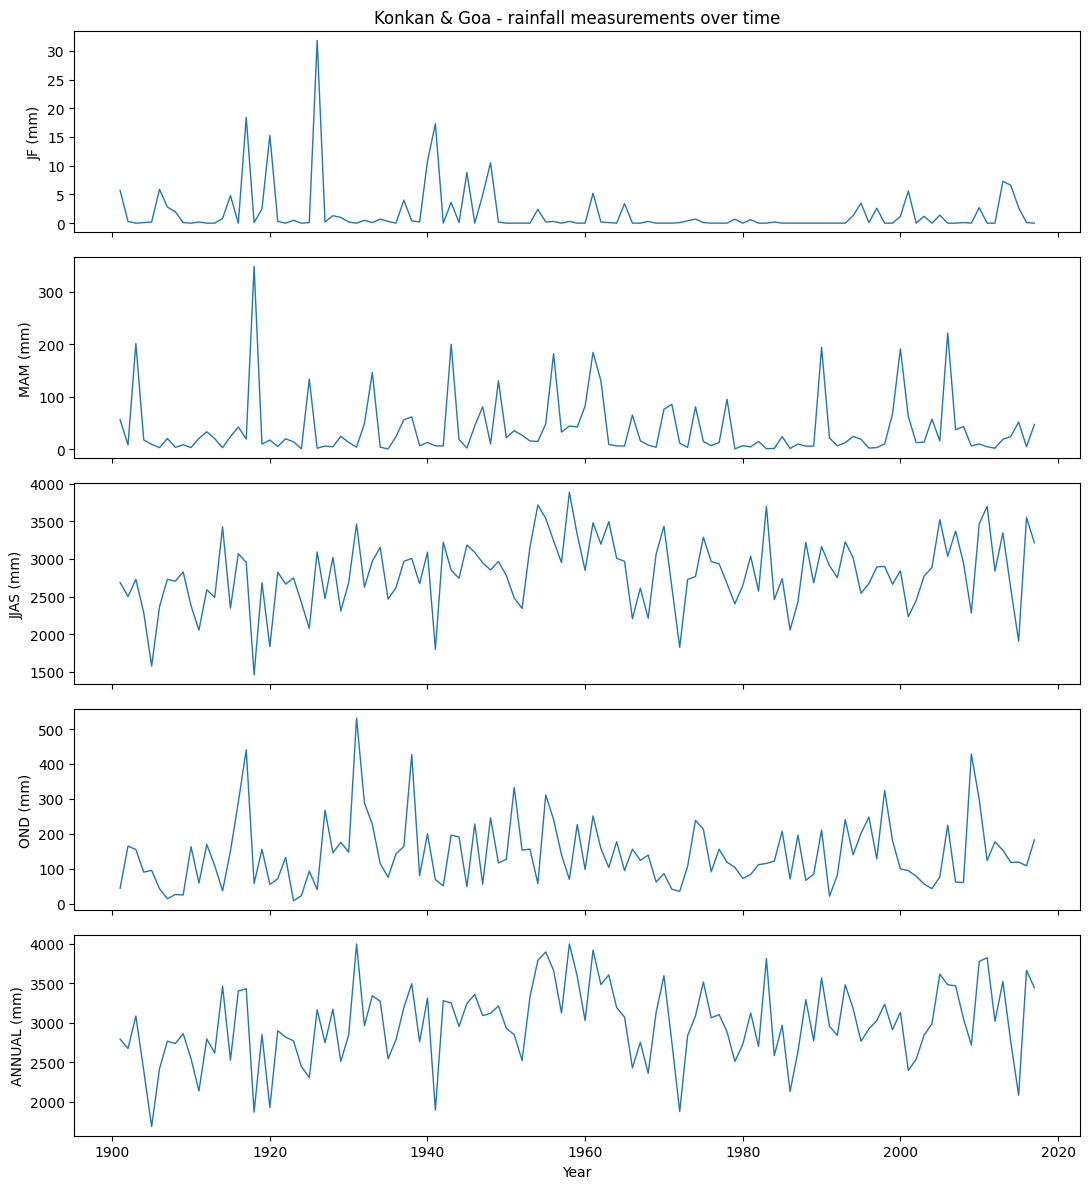

In [5]:
goa = df[df['SUBDIVISION'] == 'Konkan & Goa'].set_index('date')

fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
for ax, col in zip(axes, sensors):
    ax.plot(goa.index, goa[col], linewidth=1)
    ax.set_ylabel(col + " (mm)")
axes[0].set_title("Konkan & Goa - rainfall measurements over time")
axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.savefig("fig1_time_series.png", dpi=120)
plt.show()

In [6]:
variation = pd.DataFrame({
    'CV %': goa[sensors].std() / goa[sensors].mean() * 100,
    'avg yearly change %': goa[sensors].diff().abs().mean() / goa[sensors].mean() * 100,
})
print(variation.round(1))

         CV %  avg yearly change %
JF      244.1                158.5
MAM     149.5                125.8
JJAS     16.4                 17.3
OND      66.7                 65.7
ANNUAL   16.3                 16.5


**Observation:** JF (Jan-Feb) rainfall varies the most over time (CV 244%, average yearly change 159%), but it is tiny in amount. JJAS and ANNUAL are the most stable (CV about 16%), so the monsoon is large and fairly steady.

## Step 7: Moving average (Result 3 - Moving average plot)

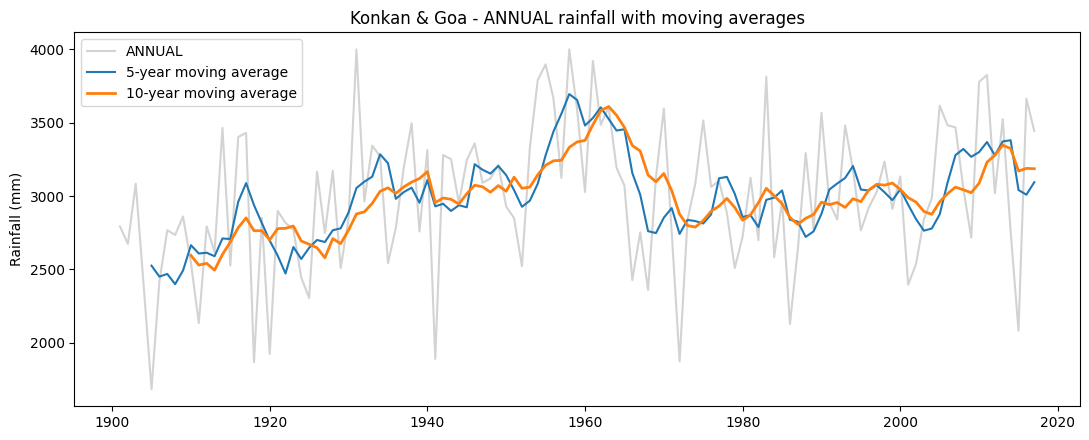

In [7]:
goa['MA5'] = goa['ANNUAL'].rolling(window=5).mean()
goa['MA10'] = goa['ANNUAL'].rolling(window=10).mean()

plt.figure(figsize=(11, 4.5))
plt.plot(goa.index, goa['ANNUAL'], color='lightgray', label='ANNUAL')
plt.plot(goa.index, goa['MA5'], label='5-year moving average')
plt.plot(goa.index, goa['MA10'], label='10-year moving average', linewidth=2)
plt.ylabel("Rainfall (mm)")
plt.title("Konkan & Goa - ANNUAL rainfall with moving averages")
plt.legend()
plt.tight_layout()
plt.savefig("fig2_moving_average.png", dpi=120)
plt.show()

In [8]:
slope, intercept, r, p, se = stats.linregress(goa['YEAR'], goa['ANNUAL'])
print(f"Trend: {slope * 10:.1f} mm per decade, p-value = {p:.3f}")

Trend: 35.6 mm per decade, p-value = 0.007


**Observation:** The 10-year moving average rises from about 2600 mm around 1910 to a peak near 3600 mm in the early 1960s and then falls back to about 2900 mm. So the trend is a slow wave rather than a straight line, with a mild overall rise of 35.6 mm per decade (p = 0.007).

## Step 8: Rolling standard deviation

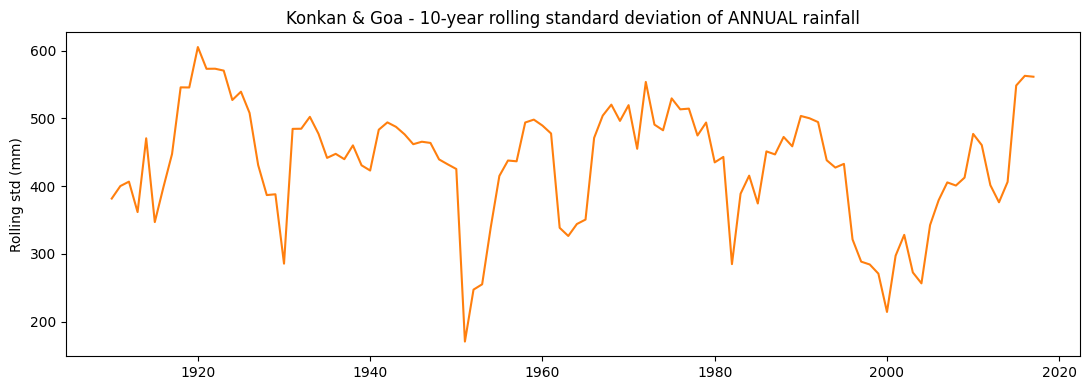

In [9]:
goa['STD10'] = goa['ANNUAL'].rolling(window=10).std()

plt.figure(figsize=(11, 4))
plt.plot(goa.index, goa['STD10'], color='tab:orange')
plt.ylabel("Rolling std (mm)")
plt.title("Konkan & Goa - 10-year rolling standard deviation of ANNUAL rainfall")
plt.tight_layout()
plt.savefig("fig3_rolling_std.png", dpi=120)
plt.show()

**Observation:** The rolling standard deviation is not constant. It drops to about 170 mm in the early 1950s and reaches about 600 mm around 1920 and again above 550 mm in 2016-17, so some decades are much more unstable than others.

## Step 9: Detect abnormal behaviour (Result 4 - Anomaly detection)
A year is abnormal if it is more than 2 rolling standard deviations away from the mean of the previous 10 years (only past data is used).

Konkan & Goa: 15 anomalies out of 107 years checked = 14.0%
            YEAR  ANNUAL     z
date                          
1914-01-01  1914  3464.6  2.68
1916-01-01  1916  3402.6  2.07
1918-01-01  1918  1867.3 -2.20
1931-01-01  1931  3999.3  4.31
1941-01-01  1941  1889.6 -3.02
1952-01-01  1952  2522.0 -3.56
1954-01-01  1954  3790.3  2.86
1955-01-01  1955  3897.5  2.22
1966-01-01  1966  2427.5 -2.97
1972-01-01  1972  1873.0 -2.56
1983-01-01  1983  3814.5  3.02
1986-01-01  1986  2127.7 -2.19
2001-01-01  2001  2395.4 -3.03
2005-01-01  2005  3615.7  2.89
2015-01-01  2015  2082.0 -3.06


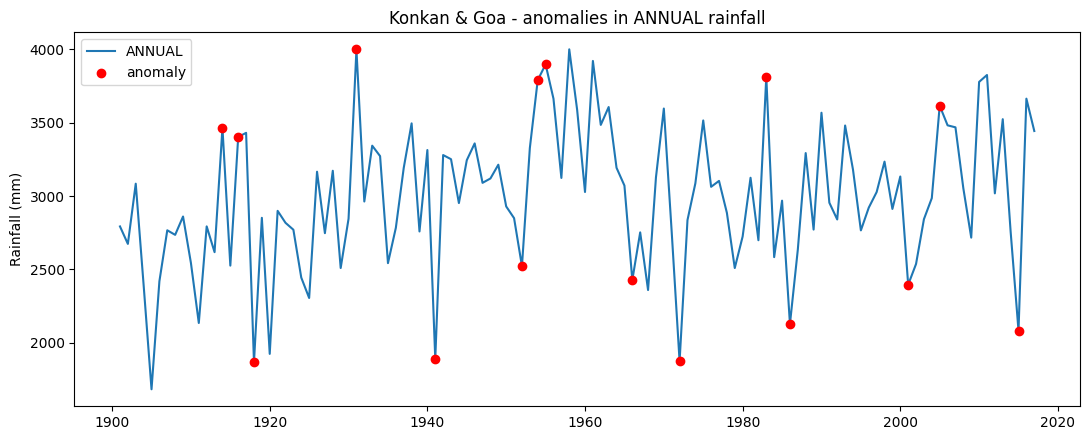

In [10]:
goa['past_mean'] = goa['ANNUAL'].rolling(10).mean().shift(1)
goa['past_std'] = goa['ANNUAL'].rolling(10).std().shift(1)
goa['z'] = (goa['ANNUAL'] - goa['past_mean']) / goa['past_std']
goa['anomaly'] = goa['z'].abs() > 2

checked = goa['z'].notnull().sum()
n_anom = goa['anomaly'].sum()
print(f"Konkan & Goa: {n_anom} anomalies out of {checked} years checked = {n_anom / checked * 100:.1f}%")
print(goa.loc[goa['anomaly'], ['YEAR', 'ANNUAL', 'z']].round(2).to_string())

plt.figure(figsize=(11, 4.5))
plt.plot(goa.index, goa['ANNUAL'], label='ANNUAL')
plt.scatter(goa.index[goa['anomaly']], goa['ANNUAL'][goa['anomaly']], color='red', zorder=3, label='anomaly')
plt.ylabel("Rainfall (mm)")
plt.title("Konkan & Goa - anomalies in ANNUAL rainfall")
plt.legend()
plt.tight_layout()
plt.savefig("fig4_anomalies.png", dpi=120)
plt.show()

In [11]:
g = ts.groupby('SUBDIVISION')['ANNUAL']
ts['z'] = (ts['ANNUAL'] - g.transform(lambda s: s.rolling(10).mean().shift(1))) / \
          g.transform(lambda s: s.rolling(10).std().shift(1))
ts['anomaly'] = ts['z'].abs() > 2

checked_all = ts['z'].notnull().sum()
print(f"All subdivisions: {ts['anomaly'].sum()} anomalies out of {checked_all} = {ts['anomaly'].sum() / checked_all * 100:.1f}%")
print("  too wet (z > 2):", (ts['z'] > 2).sum(), "  too dry (z < -2):", (ts['z'] < -2).sum())

All subdivisions: 387 anomalies out of 3788 = 10.2%
  too wet (z > 2): 228   too dry (z < -2): 159


**Observation:** 14.0% of Konkan & Goa years (15 of 107) and 10.2% of all subdivision-years (387 of 3788) are flagged. Wet anomalies (228) are more common than dry ones (159). The rule compares each year only with the previous 10 years, so it flags years that are unusual for the recent decade.

## Step 10: Create time-series features
Everything is turned into % of the subdivision's average (1901-1995 only), because rainfall differs 10x between regions.

In [12]:
split_year = 1995

train_mean = ts[ts['YEAR'] <= split_year].groupby('SUBDIVISION')['ANNUAL'].mean()
ts['rel'] = ts['ANNUAL'] / ts['SUBDIVISION'].map(train_mean) * 100

g = ts.groupby('SUBDIVISION')['rel']
ts['rel_now'] = ts['rel']
ts['rel_prev'] = g.shift(1)
ts['ma5'] = g.transform(lambda s: s.rolling(5).mean())
ts['ma10'] = g.transform(lambda s: s.rolling(10).mean())
ts['std5'] = g.transform(lambda s: s.rolling(5).std())
ts['diff1'] = g.diff()
ts['trend'] = ts['ma5'] - ts['ma10']

for c in ['JF', 'MAM', 'JJAS', 'OND']:
    ts[c + '_share'] = ts[c] / ts['ANNUAL'] * 100

features = ['rel_now', 'rel_prev', 'ma5', 'ma10', 'std5', 'diff1', 'trend',
            'JF_share', 'MAM_share', 'JJAS_share', 'OND_share']
print(ts[['SUBDIVISION', 'YEAR'] + features].dropna().head(3).round(1).to_string())

                  SUBDIVISION  YEAR  rel_now  rel_prev   ma5  ma10  std5  diff1  trend  JF_share  MAM_share  JJAS_share  OND_share
18  Andaman & Nicobar Islands  1919     80.1     111.6  94.8  94.7  11.8  -31.4    0.2       1.2       13.6        51.8       33.4
19  Andaman & Nicobar Islands  1920    100.3      80.1  96.2  94.8  12.0   20.1    1.4       4.4        8.6        61.6       25.3
20  Andaman & Nicobar Islands  1921     88.8     100.3  94.0  94.6  12.2  -11.5   -0.6       0.6       14.9        64.5       20.0


## Step 11: Prepare data for failure prediction
Failure = ANNUAL rainfall below 80% of the subdivision's average. The model uses the data up to year t to predict whether year t+1 is a failure.

In [13]:
ts['drought'] = np.where(ts['rel'].isnull(), np.nan, (ts['rel'] < 80).astype(float))
ts['target'] = ts.groupby('SUBDIVISION')['drought'].shift(-1)

data = ts.dropna(subset=features + ['target']).copy()
data['target'] = data['target'].astype(int)
print("Rows for modelling:", len(data))
print("Failure years (target = 1):", data['target'].sum(), f"({data['target'].mean() * 100:.1f}%)")

Rows for modelling: 3788
Failure years (target = 1): 582 (15.4%)


## Step 12: Split into training and testing sets
Split by time, NOT randomly: train on the past, test on the later years.

In [14]:
train = data[data['YEAR'] + 1 <= split_year]
test = data[data['YEAR'] + 1 > split_year]

X_train, y_train = train[features], train['target']
X_test, y_test = test[features], test['target']

print(f"Train: {len(train)} rows, target years up to {split_year}, failure rate {y_train.mean() * 100:.1f}%")
print(f"Test : {len(test)} rows, target years {split_year + 1}-2017, failure rate {y_test.mean() * 100:.1f}%")

Train: 2996 rows, target years up to 1995, failure rate 13.4%
Test : 792 rows, target years 1996-2017, failure rate 22.9%


## Step 13: Train the failure prediction model

In [15]:
model = RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=10,
                               class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print("Model trained on", len(X_train), "rows with", len(features), "features")

Model trained on 2996 rows with 11 features


## Step 14: Evaluate the model (Result 5 - Failure prediction)

In [16]:
def scores(name, y_true, y_pred, y_prob=None):
    row = {'model': name,
           'accuracy': accuracy_score(y_true, y_pred),
           'precision': precision_score(y_true, y_pred, zero_division=0),
           'recall': recall_score(y_true, y_pred, zero_division=0),
           'F1': f1_score(y_true, y_pred, zero_division=0)}
    row['ROC-AUC'] = roc_auc_score(y_true, y_prob) if y_prob is not None else 0.5
    return row

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

results = pd.DataFrame([scores('Random Forest', y_test, pred, prob),
                        scores('Always "no failure"', y_test, baseline.predict(X_test))])
print(results.round(3).to_string(index=False))

cm = confusion_matrix(y_test, pred)
print("\nConfusion matrix (rows = actual, columns = predicted)")
print(pd.DataFrame(cm, index=['actual normal', 'actual failure'], columns=['pred normal', 'pred failure']))

              model  accuracy  precision  recall    F1  ROC-AUC
      Random Forest     0.688      0.362   0.481 0.413    0.634
Always "no failure"     0.771      0.000   0.000 0.000    0.500

Confusion matrix (rows = actual, columns = predicted)
                pred normal  pred failure
actual normal           458           153
actual failure           94            87


**Observation:** The model finds 87 of the 181 failure years in the test period (recall 0.48) but gives 153 false alarms (precision 0.36). The always-no-failure baseline has higher accuracy (0.771) only because it never catches a failure. ROC-AUC is 0.63, a modest skill above random guessing (0.5). The test period also has more failures (22.9%) than the training period (13.4%), which makes the task harder.

## Step 15: Interpret the results

std5          0.168
diff1         0.112
rel_prev      0.107
rel_now       0.098
MAM_share     0.097
OND_share     0.089
JJAS_share    0.074
ma10          0.074
trend         0.065
ma5           0.062
JF_share      0.056


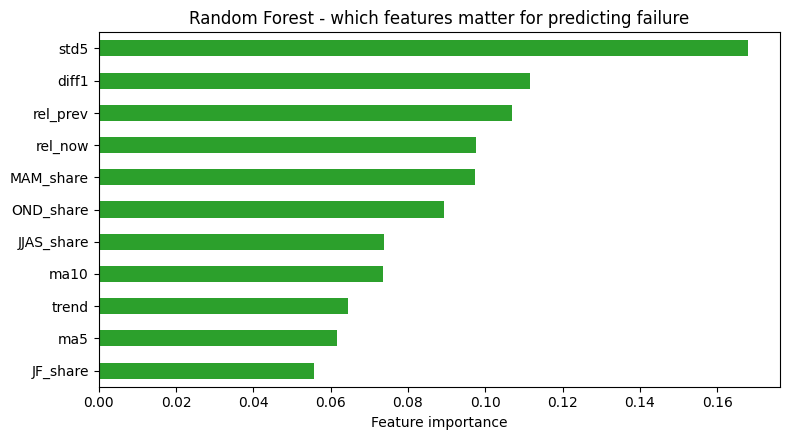

In [17]:
importance = pd.Series(model.feature_importances_, index=features).sort_values(ascending=False)
print(importance.round(3).to_string())

plt.figure(figsize=(8, 4.5))
importance.sort_values().plot(kind='barh', color='tab:green')
plt.xlabel("Feature importance")
plt.title("Random Forest - which features matter for predicting failure")
plt.tight_layout()
plt.savefig("fig5_feature_importance.png", dpi=120)
plt.show()

In [18]:
check = data[data['z'].notnull()]
after_anomaly = check['z'].abs() > 2
rate_after_anomaly = check.loc[after_anomaly, 'target'].mean() * 100
rate_after_normal = check.loc[~after_anomaly, 'target'].mean() * 100
print(f"Failure next year after an anomalous year : {rate_after_anomaly:.1f}%  ({after_anomaly.sum()} cases)")
print(f"Failure next year after a normal year     : {rate_after_normal:.1f}%  ({(~after_anomaly).sum()} cases)")

Failure next year after an anomalous year : 18.4%  (386 cases)
Failure next year after a normal year     : 14.8%  (3363 cases)


**Observation:** Failure rate after an anomalous year is 18.4% against 14.8% after a normal year, only a small increase. Feature importance is spread out, with the 5-year moving standard deviation (std5, 0.168) on top and the change since last year (diff1, 0.112) second.

## Answers to the Step 15 questions
1. **Strongest temporal variation:** JF rainfall (CV 244%).
2. **Abnormal values before failures:** only slightly. A failure year followed an anomalous year 18.4% of the time against 14.8% after a normal year.
3. **Moving average trend:** yes, a slow rise to the early 1960s and a fall afterwards, with a mild overall upward trend of 35.6 mm per decade.
4. **Anomalies:** 14.0% of Konkan & Goa years and 10.2% of all subdivision-years.
5. **Model accuracy:** accuracy 0.688, recall 0.48, precision 0.36, F1 0.41, ROC-AUC 0.63 on the 1996-2017 test years.
6. **Most useful features:** std5 (recent variability), diff1 (change from last year) and rel_prev (last year's rainfall).

## Conclusion
Rainfall was treated as a yearly time series: Konkan & Goa shows a slow multi-decade swing and 14% anomalous years, and 10% of all subdivision-years are anomalous. A Random Forest using lag, moving average, rolling standard deviation and change features predicted next-year deficient rainfall with only modest skill (ROC-AUC 0.63, recall 0.48, precision 0.36). Rainfall depends on many things besides last year's rainfall, so such a model can only be a rough early-warning signal.